In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import random
import types

from time import time

from scipy.special import comb, loggamma, lambertw
from scipy.stats import multinomial, expon

from silence_tensorflow import silence_tensorflow
silence_tensorflow()
import tensorflow as tf
import tensorflow_probability as tfp
from tensorflow import keras
from tensorflow.keras import optimizers, initializers, regularizers, layers

config = tf.compat.v1.ConfigProto()
config.gpu_options.allow_growth = True
sess = tf.compat.v1.Session(config = config)

import os, shutil
from pathlib import Path
import json
import subprocess

import lifelines
from lifelines.utils import concordance_index
from lifelines.statistics import logrank_test

import sys
sys.path.insert(0, "../src")
from package import cure_aft
from package import gndr_utils as utils
from package import evaluation_metrics as evaluations

import thetaflow as thf

E0000 00:00:1793254492.676677   29181 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793254492.681853   29181 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793254492.694875   29181 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793254492.694902   29181 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793254492.694905   29181 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793254492.694908   29181 computation_placer.cc:177] computation placer already registered. Please check linka

In this notebook, we will compare models from all proposed structures (1, 2, 3 and 4), considering different combinations of regressions over the parameters in three families from the cure AFT survival family of survival models.

We will be considering as criterions mainly the Integrated Brier Score (IBS) over the test set and the Anderson-Darling test statistic for the normalized quantile residuals in the test set in order to select the best fit model.

In [2]:
df_clean_train = pd.read_csv("../data/00_clean/metabric_train_data.csv")
df_clean_test = pd.read_csv("../data/00_clean/metabric_test_data.csv")

df_train = pd.read_csv("../data/01_mlready/metabric_train.csv")
df_test = pd.read_csv("../data/01_mlready/metabric_test.csv")

print("Train data dimension: {}".format(df_train.shape))
print("Test data dimension: {}".format(df_test.shape))

# Lifetimes and censoring indicators
y_train = df_train["time"] / 12
delta_train = df_train["delta"]
# Data for the neural network interpreter
X_train_nn = df_train.iloc[:, 10:]
# For all parameters from the AFT model, consider the same set of features as predictors
z_train_mu = df_train.iloc[:, 3:10]
z_train_mu.insert(0, "const", 1)
z_train_sigma = df_train.iloc[:, 5:10]
z_train_sigma.insert(0, "const", 1)
z_train_p = df_train.iloc[:, 3:10]
z_train_p.insert(0, "const", 1)

# Lifetimes and censoring indicators
y_test = df_test["time"] / 12
delta_test = df_test["delta"]
# Data for the neural network interpreter
X_test_nn = df_test.iloc[:, 10:]
# For all parameters from the AFT model, consider the same set of features as predictors
z_test_mu = df_test.iloc[:, 3:10]
z_test_mu.insert(0, "const", 1)
z_test_sigma = df_test.iloc[:, 5:10]
z_test_sigma.insert(0, "const", 1)
z_test_p = df_test.iloc[:, 3:10]
z_test_p.insert(0, "const", 1)

data_train = [z_train_mu, z_train_sigma, z_train_p, y_train, delta_train]
data_test = [z_test_mu, z_test_sigma, z_test_p, y_test, delta_test]

Train data dimension: (1386, 183)
Test data dimension: (463, 183)


In [3]:
def load_model(structure, filename, survival_cure_function,
               model_parameters, model_loss, nn_arch, nn_call, nn_call_nolast,
               y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
               y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p):
    
    if(structure == 1):
        model = thf.ModelNN(model_parameters, model_loss, seed = 10)
    else:
        model = thf.ModelNN(model_parameters, model_loss,
                            nn_arch, nn_call, nn_call_nolast,
                            input_dim = (X_train_nn.shape[1], ), seed = 10)

    if(structure == 1):
        model(None)
    model.load_model( "../model_weights/Classic Holdout/Structure{}/{}".format(structure, filename) )
    
    if(structure == 1):
        model_summary = survival_cure_function(model,
                                               y_train, delta_train, z_train_mu, z_train_sigma, z_train_p,
                                               y_test, delta_test, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
    else:
        model_summary = survival_cure_function(model,
                                               y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p,
                                               y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p, ngrid = 100)
    return model, model_summary

### Structure 1

In [4]:
wb_parameters1, wb_loss1, wb_survival_cure1 = cure_aft.build_cure_aft_structure1("wb", z_train_mu, z_train_sigma, z_train_p)
ln_parameters1, ln_loss1, ln_survival_cure1 = cure_aft.build_cure_aft_structure1("ln", z_train_mu, z_train_sigma, z_train_p)
ll_parameters1, ll_loss1, ll_survival_cure1 = cure_aft.build_cure_aft_structure1("ll", z_train_mu, z_train_sigma, z_train_p)

wb_model1, wb_summary1 = load_model(1, "wb_model", wb_survival_cure1,
                                    wb_parameters1, wb_loss1, None, None, None,
                                    y_train, delta_train, None, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, None, z_test_mu, z_test_sigma, z_test_p)
ln_model1, ln_summary1 = load_model(1, "ln_model", ln_survival_cure1,
                                    ln_parameters1, ln_loss1, None, None, None,
                                    y_train, delta_train, None, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, None, z_test_mu, z_test_sigma, z_test_p)
ll_model1, ll_summary1 = load_model(1, "ll_model", ll_survival_cure1,
                                    ll_parameters1, ll_loss1, None, None, None,
                                    y_train, delta_train, None, z_train_mu, z_train_sigma, z_train_p,
                                    y_test, delta_test, None, z_test_mu, z_test_sigma, z_test_p)

Model successfully loaded from ../model_weights/Classic Holdout/Structure1/wb_model.
Model successfully loaded from ../model_weights/Classic Holdout/Structure1/ln_model.
Model successfully loaded from ../model_weights/Classic Holdout/Structure1/ll_model.


### Structure 2

In [5]:
wb_parameters2, wb_loss2, wb_survival_cure2 = cure_aft.build_cure_aft_structure2("wb", z_train_mu.iloc[:,1:], z_train_sigma, z_train_p)
ln_parameters2, ln_loss2, ln_survival_cure2 = cure_aft.build_cure_aft_structure2("ln", z_train_mu.iloc[:,1:], z_train_sigma, z_train_p)
ll_parameters2, ll_loss2, ll_survival_cure2 = cure_aft.build_cure_aft_structure2("ll", z_train_mu.iloc[:,1:], z_train_sigma, z_train_p)

wb_model2, wb_summary2 = load_model(2, "wb_model", wb_survival_cure2,
                                    wb_parameters2, wb_loss2, cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu.iloc[:,1:], z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu.iloc[:,1:], z_test_sigma, z_test_p)
ln_model2, ln_summary2 = load_model(2, "ln_model", ln_survival_cure2,
                                    ln_parameters2, ln_loss2, cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu.iloc[:,1:], z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu.iloc[:,1:], z_test_sigma, z_test_p)
ll_model2, ll_summary2 = load_model(2, "ll_model", ll_survival_cure2,
                                    ll_parameters2, ll_loss2, cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu.iloc[:,1:], z_train_sigma, z_train_p,
                                    y_test, delta_test, X_test_nn, z_test_mu.iloc[:,1:], z_test_sigma, z_test_p)

Model successfully loaded from ../model_weights/Classic Holdout/Structure2/wb_model.
Model successfully loaded from ../model_weights/Classic Holdout/Structure2/ln_model.
Model successfully loaded from ../model_weights/Classic Holdout/Structure2/ll_model.


### Structure 3

In [6]:
wb_parameters3, wb_loss3, wb_survival_cure3 = cure_aft.build_cure_aft_structure3("wb", z_train_mu, z_train_sigma, z_train_p.iloc[:,1:])
ln_parameters3, ln_loss3, ln_survival_cure3 = cure_aft.build_cure_aft_structure3("ln", z_train_mu, z_train_sigma, z_train_p.iloc[:,1:])
ll_parameters3, ll_loss3, ll_survival_cure3 = cure_aft.build_cure_aft_structure3("ll", z_train_mu, z_train_sigma, z_train_p.iloc[:,1:])

wb_model3, wb_summary3 = load_model(3, "wb_model", wb_survival_cure3,
                                    wb_parameters3, wb_loss3, cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p.iloc[:,1:],
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p.iloc[:,1:])
ln_model3, ln_summary3 = load_model(3, "ln_model", ln_survival_cure3,
                                    ln_parameters3, ln_loss3, cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p.iloc[:,1:],
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p.iloc[:,1:])
ll_model3, ll_summary3 = load_model(3, "ll_model", ll_survival_cure3,
                                    ll_parameters3, ll_loss3, cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu, z_train_sigma, z_train_p.iloc[:,1:],
                                    y_test, delta_test, X_test_nn, z_test_mu, z_test_sigma, z_test_p.iloc[:,1:])

Model successfully loaded from ../model_weights/Classic Holdout/Structure3/wb_model.
Model successfully loaded from ../model_weights/Classic Holdout/Structure3/ln_model.
Model successfully loaded from ../model_weights/Classic Holdout/Structure3/ll_model.


### Structure 4

In [7]:
wb_parameters4, wb_loss4, wb_survival_cure4 = cure_aft.build_cure_aft_structure4("wb", z_train_mu.iloc[:,1:], z_train_sigma, z_train_p.iloc[:,1:])
ln_parameters4, ln_loss4, ln_survival_cure4 = cure_aft.build_cure_aft_structure4("ln", z_train_mu.iloc[:,1:], z_train_sigma, z_train_p.iloc[:,1:])
ll_parameters4, ll_loss4, ll_survival_cure4 = cure_aft.build_cure_aft_structure4("ll", z_train_mu.iloc[:,1:], z_train_sigma, z_train_p.iloc[:,1:])

wb_model4, wb_summary4 = load_model(4, "wb_model", wb_survival_cure4,
                                    wb_parameters4, wb_loss4, cure_aft.neural_network2, cure_aft.network_call, cure_aft.network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu.iloc[:,1:], z_train_sigma, z_train_p.iloc[:,1:],
                                    y_test, delta_test, X_test_nn, z_test_mu.iloc[:,1:], z_test_sigma, z_test_p.iloc[:,1:])
ln_model4, ln_summary4 = load_model(4, "ln_model", ln_survival_cure4,
                                    ln_parameters4, ln_loss4, cure_aft.neural_network2, cure_aft.network_call, cure_aft.network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu.iloc[:,1:], z_train_sigma, z_train_p.iloc[:,1:],
                                    y_test, delta_test, X_test_nn, z_test_mu.iloc[:,1:], z_test_sigma, z_test_p.iloc[:,1:])
ll_model4, ll_summary4 = load_model(4, "ll_model", ll_survival_cure4,
                                    ll_parameters4, ll_loss4, cure_aft.neural_network2, cure_aft.network_call, cure_aft.network_call_nolast,
                                    y_train, delta_train, X_train_nn, z_train_mu.iloc[:,1:], z_train_sigma, z_train_p.iloc[:,1:],
                                    y_test, delta_test, X_test_nn, z_test_mu.iloc[:,1:], z_test_sigma, z_test_p.iloc[:,1:])

Model successfully loaded from ../model_weights/Classic Holdout/Structure4/wb_model.
Model successfully loaded from ../model_weights/Classic Holdout/Structure4/ln_model.
Model successfully loaded from ../model_weights/Classic Holdout/Structure4/ll_model.


In [9]:
wb_models = [wb_summary1, wb_summary2, wb_summary3, wb_summary4]
ln_models = [ln_summary1, ln_summary2, ln_summary3, ln_summary4]
ll_models = [ll_summary1, ll_summary2, ll_summary3, ll_summary4]

wb_ad_statistics = []
ln_ad_statistics = []
ll_ad_statistics = []

wb_ibs = []
ln_ibs = []
ll_ibs = []

for i in range(len(wb_models)):
    wb_ad_statistics.append( float(evaluations.calculate_ad_statistic(wb_models[i])) )
    ln_ad_statistics.append( float(evaluations.calculate_ad_statistic(ln_models[i])) )
    ll_ad_statistics.append( float(evaluations.calculate_ad_statistic(ll_models[i])) )

    wb_ibs.append( float(evaluations.calculate_integrated_ipcw_brier_score(wb_models[i])) )
    ln_ibs.append( float(evaluations.calculate_integrated_ipcw_brier_score(ln_models[i])) )
    ll_ibs.append( float(evaluations.calculate_integrated_ipcw_brier_score(ll_models[i])) )

scenario = list(np.repeat([1,2,3,4], 3))
model = ["wb", "ln", "ll"] * 4

metrics = pd.DataFrame({"scenario": scenario,
                        "model": model,
                        "AD": wb_ad_statistics + ln_ad_statistics + ll_ad_statistics,
                        "IBS": wb_ibs + ln_ibs + ll_ibs})
metrics.sort_values(by = "AD")

,scenario,model,AD,IBS
8,3,ll,0.000633,0.190298
6,3,wb,0.000904,0.220070
4,2,ln,0.001048,0.190351
10,4,ln,0.001110,0.223392
0,1,wb,0.001341,0.192760
2,1,ll,0.001619,0.216102
7,3,ln,0.001736,0.221006
11,4,ll,0.001860,0.238176
1,1,ln,0.002837,0.206088
3,2,wb,0.003558,0.230312


According to both AD and IBS metrics, we select the Log-logistic model from Scenario 3. That means that the model that best fit the data according to both metrics considers the AFT cure model with
\begin{align*}
    \mu &= \boldsymbol z_\mu^\top \boldsymbol \beta_\mu\\
    \sigma &= \boldsymbol z_\sigma^\top \boldsymbol \beta_\sigma\\
    p &= \boldsymbol z_p^\top \boldsymbol \beta_p + \mathcal{F}(\boldsymbol x_i ; \boldsymbol \omega)
\end{align*}
That is. By considering an extra neural network component to handle the gene mutations specifically, we are able to obtain a better model performance than the simple, linear model considering only the clinical variables.

Considering this single model, we evaluate the matrix of linear coefficients as well as check the statistical significance of the neural network predictor inside the individual-wise cure rate parameter.

In [10]:
pd.options.display.float_format = '{:.6f}'.format
mu_colnames = list( np.char.add("mu_", list(z_train_mu.columns)) )
sigma_colnames = list( np.char.add("sigma_", list(z_train_sigma.columns)) )
p_colnames = list( np.char.add("p_", list(z_train_p.iloc[:,1:].columns)) )
colnames = mu_colnames + sigma_colnames + p_colnames

display( cure_aft.summary_betas(ll_model3, colnames) )
pd.options.display.float_format = None

/home/natan/.pyenv/versions/3.10.17/lib/python3.10/site-packages/thetaflow/modelnn.py:2871: UserWarning: Model supports both neural network modeled parameters and independent parameters.
As a list of input values, x, was not provided, obtaining the covariances only for ['mu_beta', 'sigma_beta', 'p_beta'].
  warnings.warn(


,Coef,Se,Z,pvalue,CI(95%)
mu_const,2.314677,0.183355,12.623989,0.000000,(1.9553 ; 2.674)
mu_age_at_diagnosis,0.033347,0.059848,0.557192,0.577396,(-0.084 ; 0.1506)
mu_npi,-0.148422,0.059541,-2.492772,0.012675,(-0.2651 ; -0.0317)
mu_pam50_subtype_Basal,-1.485546,0.264098,-5.624988,0.000000,(-2.0032 ; -0.9679)
mu_pam50_subtype_Her2,-1.147177,0.193744,-5.921088,0.000000,(-1.5269 ; -0.7674)
mu_pam50_subtype_LumB,-0.722624,0.210767,-3.428537,0.000607,(-1.1357 ; -0.3095)
mu_pam50_subtype_Normal,-0.364498,0.268718,-1.356430,0.174962,(-0.8912 ; 0.1622)
mu_pam50_subtype_claudin-low,-0.067780,0.492328,-0.137673,0.890499,(-1.0327 ; 0.8972)
sigma_const,-0.355534,0.091510,-3.885208,0.000102,(-0.5349 ; -0.1762)
sigma_pam50_subtype_Basal,-0.037984,0.223836,-0.169695,0.865250,(-0.4767 ; 0.4007)


In [45]:
p_nn_summary_train = ll_model3.summary(X_train_nn).iloc[:,-4:]
display(p_nn_summary_train)

p_nn_summary_test = ll_model3.summary(X_test_nn).iloc[:,-4:]

,p_nn,p_nn_se,p_nn_lower,p_nn_upper
0,-1.187700,0.481522,-2.131466,-0.243935
1,-0.151480,0.644964,-1.415586,1.112627
2,-0.550335,0.639402,-1.803539,0.702869
3,-0.732233,0.364418,-1.446480,-0.017986
4,-1.575120,0.717972,-2.982321,-0.167920
...,...,...,...,...
1381,0.110027,0.381778,-0.638244,0.858298
1382,-0.408388,0.359638,-1.113266,0.296491
1383,-1.341122,0.570337,-2.458961,-0.223282
1384,-0.240623,0.764695,-1.739398,1.258152


Pacientes cujos genes tiveram predição significativa - Treino: 0.4062049062049062
Pacientes cujos genes tiveram predição significativa - Test: 0.4146868250539957


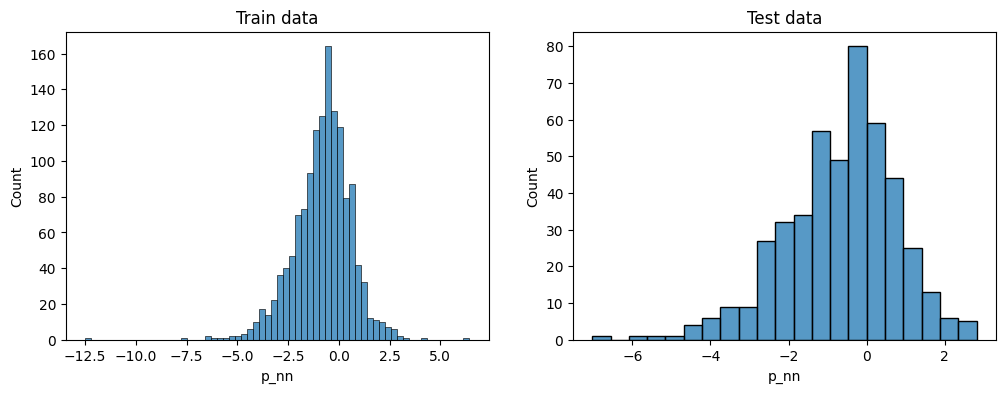

In [47]:
# Identify patients for which their corresponding genes were statistically significant for their prediction
significant_p_nn_train = ((p_nn_summary_train["p_nn_lower"] > 0) & (p_nn_summary_train["p_nn_upper"] > 0)) | ((p_nn_summary_train["p_nn_lower"] < 0) & (p_nn_summary_train["p_nn_upper"] < 0))
significant_p_nn_test = ((p_nn_summary_test["p_nn_lower"] > 0) & (p_nn_summary_test["p_nn_upper"] > 0)) | ((p_nn_summary_test["p_nn_lower"] < 0) & (p_nn_summary_test["p_nn_upper"] < 0))

print("Pacientes cujos genes tiveram predição significativa - Treino: {}".format( np.mean(significant_p_nn_train) ))
print("Pacientes cujos genes tiveram predição significativa - Test: {}".format( np.mean(significant_p_nn_test) ))

fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12,4))

sns.histplot( p_nn_summary_train.loc[:, "p_nn"], ax = ax[0] )
sns.histplot( p_nn_summary_test.loc[:, "p_nn"], ax = ax[1] )

ax[0].set_title("Train data")
ax[1].set_title("Test data")
plt.show()